# Movie Success Prediction
#### Both model (Regression & Classification)
# Problem Statement
#### Predict the Revenue based on budget using Regression Model
#### Predict the Success (Or) Flop based on badget and revenue using classification 
# Use Cases
#### Production House to Dicide how much to invest
#### OTT platform to forecast audience interest
#### Marketers & Advertisers identify the movie scaore


# Step 1: Import Libraries

In [230]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error



# Step 2: Load Dataset

In [101]:
movie_rev=pd.read_csv('TMDB_movie_dataset_v11.csv')
movie_rev.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.36,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.95,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.42,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.24,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.51,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.64,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.57,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.93,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.71,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.08,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


# Step 3 : Basic Info

In [102]:
print(movie_rev.shape)
print(movie_rev.info())

(1538765, 24)
<class 'pandas.DataFrame'>
RangeIndex: 1538765 entries, 0 to 1538764
Data columns (total 24 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   id                    1538765 non-null  int64  
 1   title                 1538745 non-null  str    
 2   vote_average          1538765 non-null  float64
 3   vote_count            1538765 non-null  int64  
 4   status                1538765 non-null  str    
 5   release_date          1163941 non-null  str    
 6   revenue               1538765 non-null  int64  
 7   runtime               1538765 non-null  int64  
 8   adult                 1538765 non-null  bool   
 9   backdrop_path         371773 non-null   str    
 10  budget                1538765 non-null  int64  
 11  homepage              156781 non-null   str    
 12  imdb_id               696559 non-null   str    
 13  original_language     1538765 non-null  str    
 14  original_title        1538745 n

In [103]:
movie_rev.isna().sum()

id                            0
title                        20
vote_average                  0
vote_count                    0
status                        0
release_date             374824
revenue                       0
runtime                       0
adult                         0
backdrop_path           1166992
budget                        0
homepage                1381984
imdb_id                  842206
original_language             0
original_title               20
overview                 362573
popularity                    0
poster_path              569684
tagline                 1323738
genres                   697407
production_companies     898519
production_countries     768676
spoken_languages         738358
keywords                1168608
dtype: int64

In [104]:
## create the column for classification

In [105]:
movie_rev['hit_flop']=movie_rev.apply(lambda row : "Hit" if row['revenue']>row['budget'] else "Flop",axis=1)

In [106]:
## check balance

In [107]:
movie_rev['hit_flop'].value_counts() ## flop tha athigama iruku hit ah vida so data is imbalanced

hit_flop
Flop    1520863
Hit       17902
Name: count, dtype: int64

In [108]:
movie_rev.describe() ## imbalanced data (revenue,runtime,budget,popularity) min value

,id,vote_average,vote_count,revenue,runtime,budget,popularity
count,"1,538,765.00","1,538,765.00","1,538,765.00","1,538,765.00","1,538,765.00","1,538,765.00","1,538,765.00"
mean,"965,773.23",1.45,13.95,"596,409.61",42.64,"226,667.45",0.93
std,"512,883.69",2.79,273.87,"19,672,095.21",60.22,"5,289,400.07",6.54
min,2.00,0.00,0.00,-12.00,-28.00,0.00,0.00
25%,"529,884.00",0.00,0.00,0.00,0.00,0.00,0.01
50%,"993,465.00",0.00,0.00,0.00,15.00,0.00,0.60
75%,"1,409,793.00",0.00,0.00,0.00,84.00,0.00,0.65
max,"1,824,677.00",10.00,"34,495.00","4,999,999,999.00","14,400.00","999,999,999.00","2,994.36"


In [109]:
## checking missing value

In [110]:
missing_cols=movie_rev.isna().sum()
missing_cols=missing_cols[missing_cols>0].sort_values(ascending=True)
missing_cols

title                        20
original_title               20
overview                 362573
release_date             374824
poster_path              569684
genres                   697407
spoken_languages         738358
production_countries     768676
imdb_id                  842206
production_companies     898519
backdrop_path           1166992
keywords                1168608
tagline                 1323738
homepage                1381984
dtype: int64

In [111]:
## detect the invalid rows(title column because its contain string)

In [112]:
movie_rev.dropna(subset=['title'])

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords,hit_flop
0,27205,Inception,8.36,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,"Cobb, a skilled thief who commits corporate es...",83.95,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc...",Hit
1,157336,Interstellar,8.42,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,The adventures of a group of explorers who mak...,140.24,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,...",Hit
2,155,The Dark Knight,8.51,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,Batman raises the stakes in his war on crime. ...,130.64,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f...",Hit
3,19995,Avatar,7.57,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,"In the 22nd century, a paraplegic Marine is di...",79.93,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ...",Hit
4,24428,The Avengers,7.71,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,When an unexpected enemy emerges and threatens...,98.08,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com...",Hit
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538760,931458,Doin' Da Bubble Butt 5,0.00,0,Released,2008-08-07,0,0,True,NaN,...,These Phat Ass Bubble Butts are just beggin to...,0.60,/x2E1r7c0eBy60pvJYSuF2i5yo5e.jpg,NaN,NaN,Black Ice,United States of America,NaN,NaN,Flop
1538761,931457,The Aqua Diary,0.00,0,Released,1998-01-01,0,105,False,NaN,...,The Official Aquarium Home Video - See Aqua tr...,0.60,NaN,NaN,NaN,NaN,NaN,English,NaN,Flop
1538762,931455,Abandoned Creatures,0.00,0,Released,2022-01-21,0,83,False,NaN,...,"After a beloved teacher dies, a loyal student ...",0.84,/js8oIIMVKroyGBl35nVuNG6xjXN.jpg,NaN,Horror,Untethered Productions,NaN,NaN,NaN,Flop
1538763,931454,Bomb Ass White Booty 7,0.00,0,Released,2006-09-18,0,131,True,NaN,...,An ass up face down movie. This hot chicks got...,0.60,/j80L5HeFW2DxQzTKi4GCg6Y3SlG.jpg,Fresh New Big Bootays,NaN,West Coast Productions,United States of America,NaN,NaN,Flop


In [113]:
movie_rev.shape,movie_rev.columns

((1538765, 25),
 Index(['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date',
        'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
        'imdb_id', 'original_language', 'original_title', 'overview',
        'popularity', 'poster_path', 'tagline', 'genres',
        'production_companies', 'production_countries', 'spoken_languages',
        'keywords', 'hit_flop'],
       dtype='str'))

In [114]:
## select important columns for regression

In [115]:
regression_col=['budget','vote_average','vote_count','release_date','revenue', 'runtime','popularity', 'genres','production_companies','original_language']
df_reg=movie_rev[regression_col].copy()
df_reg.shape

(1538765, 10)

In [116]:
df_reg.columns

Index(['budget', 'vote_average', 'vote_count', 'release_date', 'revenue',
       'runtime', 'popularity', 'genres', 'production_companies',
       'original_language'],
      dtype='str')

In [117]:
## checking ivalid data 

In [118]:
(df_reg['revenue']<=0).sum(),(df_reg['budget']<=0).sum(),(df_reg['runtime']<=0).sum()


(np.int64(1512871), np.int64(1447741), np.int64(493979))

In [119]:
df_reg=df_reg[(df_reg['revenue']>0)&(df_reg['budget']>0)&(df_reg['runtime']>0)]
df_reg.shape

(15536, 10)

In [120]:
df_reg.describe()

,budget,vote_average,vote_count,revenue,runtime,popularity
count,"15,536.00","15,536.00","15,536.00","15,536.00","15,536.00","15,536.00"
mean,"16,782,004.84",4.63,984.40,"50,763,193.85",89.90,12.60
std,"38,176,068.88",3.26,"2,499.40","166,063,796.05",70.12,50.28
min,1.00,0.00,0.00,1.00,1.00,0.00
25%,"1,000.00",0.00,0.00,"1,000.00",58.00,0.60
50%,"2,100,000.00",6.00,52.00,"2,157,404.50",97.00,5.69
75%,"17,000,000.00",6.90,752.00,"29,844,264.00",115.00,15.71
max,"940,000,000.00",10.00,"34,495.00","4,999,999,999.00",999.00,"2,994.36"


# Step 4: EDA
#### data va innum depth ah analys pandrathuku ovvoru column um revenue oda evlo influence aguthuthu understand pannikurathuku

In [121]:
## revenue distribution

<Axes: xlabel='revenue', ylabel='Count'>

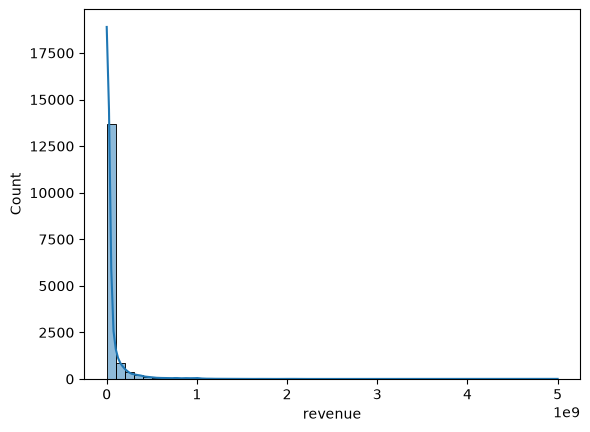

In [122]:
sns.histplot(df_reg['revenue'],bins=50,kde=True) ## 

<Axes: xlabel='revenue', ylabel='Count'>

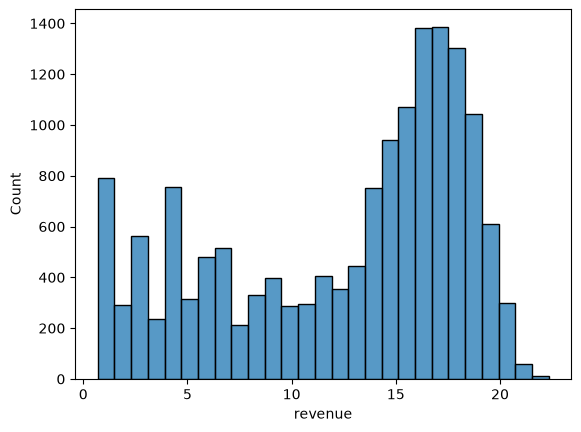

In [123]:
sns.histplot(np.log1p(df_reg['revenue'])) ## log transformed

In [124]:
## budget distribution

<Axes: xlabel='budget', ylabel='Count'>

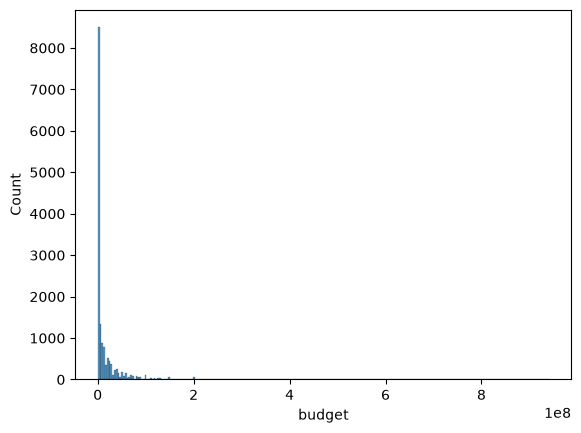

In [125]:
sns.histplot(df_reg['budget'])

<Axes: xlabel='budget', ylabel='Count'>

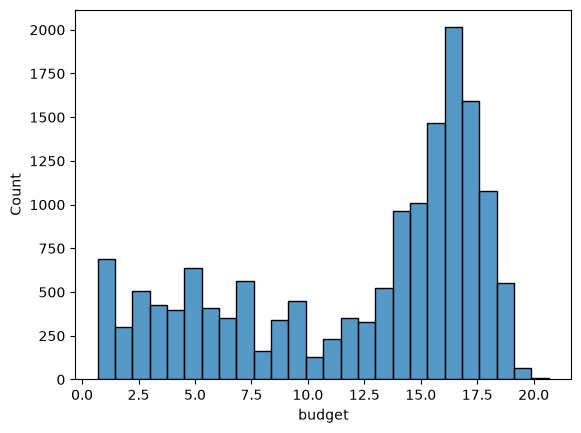

In [126]:
sns.histplot(np.log1p(df_reg['budget']))

In [127]:
## Runtime distribution

<Axes: xlabel='runtime', ylabel='Count'>

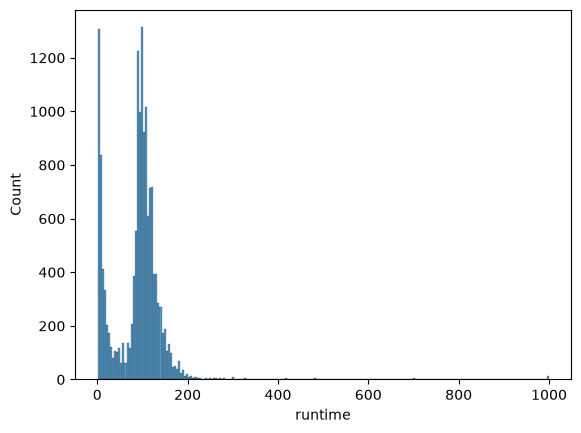

In [128]:
sns.histplot(df_reg['runtime'])

<Axes: xlabel='runtime', ylabel='Count'>

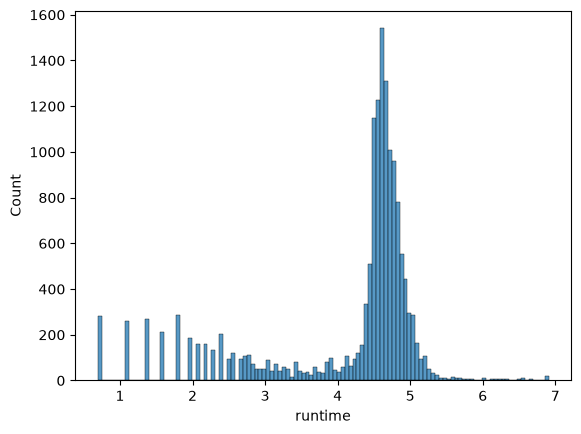

In [129]:
sns.histplot(np.log1p(df_reg['runtime']))

In [130]:
## popularity distribution

<Axes: xlabel='popularity', ylabel='Count'>

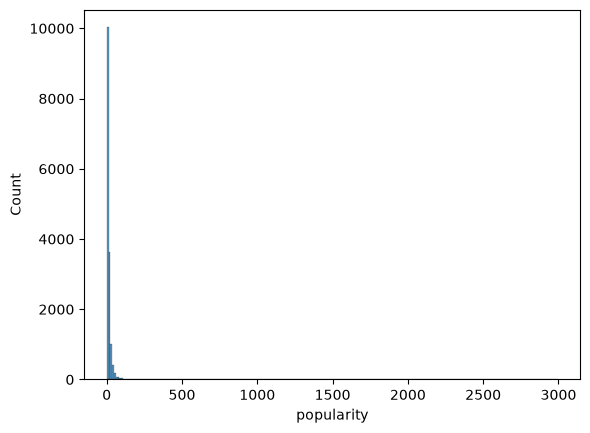

In [131]:
sns.histplot(df_reg['popularity'])

<Axes: xlabel='popularity', ylabel='Count'>

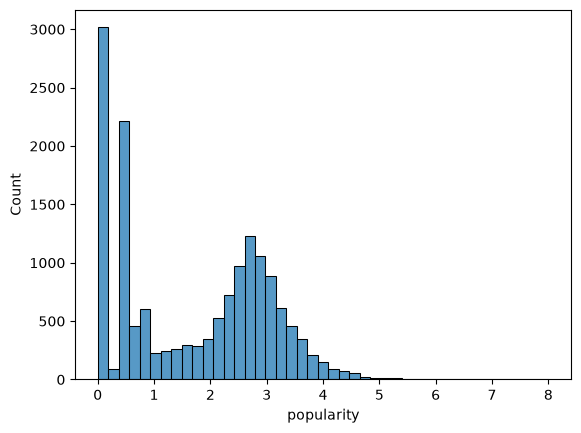

In [132]:
sns.histplot(np.log1p(df_reg['popularity']))

In [133]:
## correlation heat map

<Axes: >

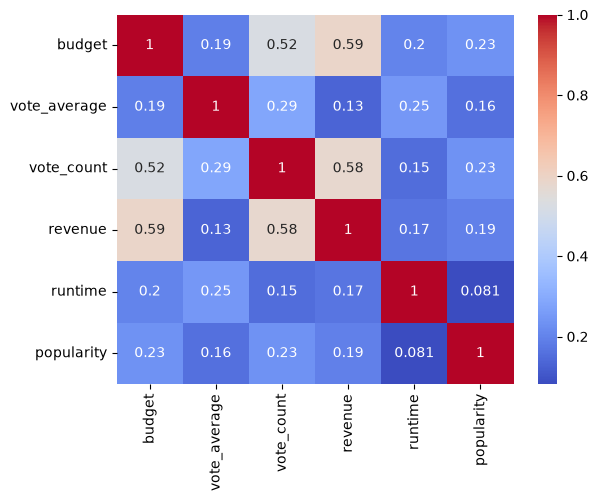

In [134]:
correlation=df_reg.select_dtypes(include='number').corr()
correlation
sns.heatmap(correlation,annot=True,cmap='coolwarm')

In [135]:
## Revenue vs Budget

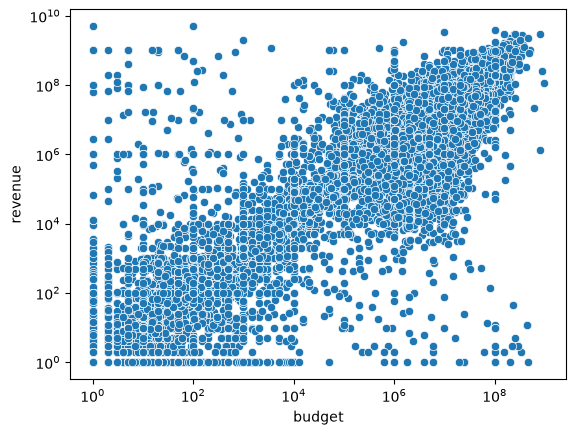

In [136]:
sns.scatterplot(data=df_reg,x='budget',y='revenue')
plt.xscale('log')
plt.yscale('log')

In [137]:
## Rev vs popularity

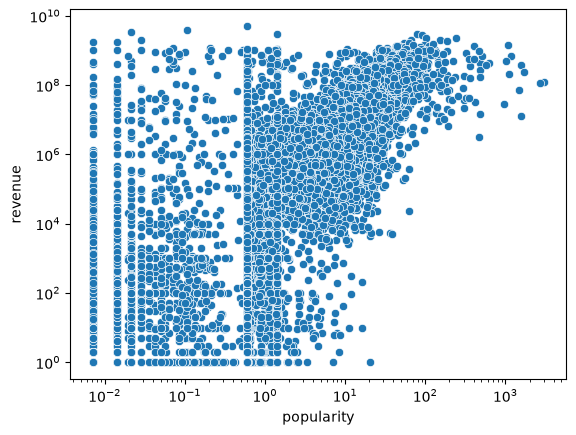

In [138]:
sns.scatterplot(data=df_reg,x='popularity',y='revenue')
plt.xscale('log')
plt.yscale('log')

In [139]:
## Release Year Trend

<Axes: xlabel='release_year'>

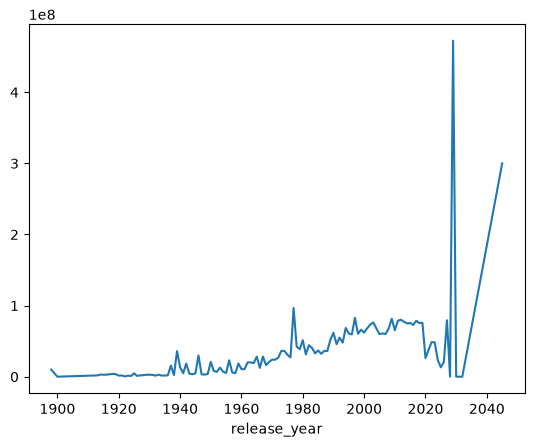

In [140]:
df_reg['release_year']=pd.to_datetime(df_reg['release_date']).dt.year
df_reg['release_year']
year_rev=df_reg.groupby('release_year')['revenue'].mean()
year_rev.plot()


In [141]:
## genres rev

In [142]:
df_reg.columns

Index(['budget', 'vote_average', 'vote_count', 'release_date', 'revenue',
       'runtime', 'popularity', 'genres', 'production_companies',
       'original_language', 'release_year'],
      dtype='str')

In [143]:
df_reg['genres']

0                   Action, Science Fiction, Adventure
1                    Adventure, Drama, Science Fiction
2                       Drama, Action, Crime, Thriller
3          Action, Adventure, Fantasy, Science Fiction
4                   Science Fiction, Action, Adventure
                              ...                     
1538241                          Comedy, Drama, Action
1538496                                            NaN
1538512                                          Drama
1538538                     Documentary, Drama, Family
1538756                        Comedy, Drama, Thriller
Name: genres, Length: 15536, dtype: str

In [144]:
# step 1: genres convert into the list

In [145]:

df_reg['genres']=df_reg['genres'].str.split(',')
df_reg['genres']


0                    [Action,  Science Fiction,  Adventure]
1                     [Adventure,  Drama,  Science Fiction]
2                       [Drama,  Action,  Crime,  Thriller]
3          [Action,  Adventure,  Fantasy,  Science Fiction]
4                    [Science Fiction,  Action,  Adventure]
                                 ...                       
1538241                           [Comedy,  Drama,  Action]
1538496                                                 NaN
1538512                                             [Drama]
1538538                      [Documentary,  Drama,  Family]
1538756                         [Comedy,  Drama,  Thriller]
Name: genres, Length: 15536, dtype: object

In [146]:
# step 2 : convert into individual row

In [147]:
df_explode=df_reg.explode('genres')
df_explode.head()

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,genres,production_companies,original_language,release_year
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Action,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Science Fiction,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Adventure,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Adventure,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00"
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Drama,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00"


In [148]:
# step 3 :remove the whitespace

In [149]:
df_explode['genres']=df_explode['genres'].str.strip()
df_explode

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,genres,production_companies,original_language,release_year
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Action,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Science Fiction,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Adventure,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00"
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Adventure,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00"
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Drama,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00"
...,...,...,...,...,...,...,...,...,...,...,...
1538538,195,0.00,0,2021-08-17,98,13,0.60,Drama,NaN,tl,"2,021.00"
1538538,195,0.00,0,2021-08-17,98,13,0.60,Family,NaN,tl,"2,021.00"
1538756,10,0.00,0,NaN,5,159,0.60,Comedy,NaN,en,NaN
1538756,10,0.00,0,NaN,5,159,0.60,Drama,NaN,en,NaN


In [150]:
# step 4 : group by the genres

In [151]:
genre_rev=df_explode.groupby(by='genres')['revenue'].mean().sort_values(ascending=False)
pd.options.display.float_format = '{:,.2f}'.format
genre_rev

genres
Adventure         156,626,220.99
Fantasy           136,888,791.27
Science Fiction   133,356,203.35
Animation         124,883,179.21
Family            114,934,607.06
Action            106,920,302.75
War                59,830,824.45
Thriller           56,711,107.00
Comedy             53,037,397.46
Crime              49,897,613.46
Music              48,538,880.51
History            48,313,271.25
Mystery            47,114,869.81
Romance            43,865,536.17
Drama              38,198,314.07
Horror             32,916,877.86
Western            32,839,037.13
TV Movie           26,605,609.00
Documentary        10,574,301.93
Name: revenue, dtype: float64

In [152]:
# step 5 : plot

<Axes: xlabel='genres'>

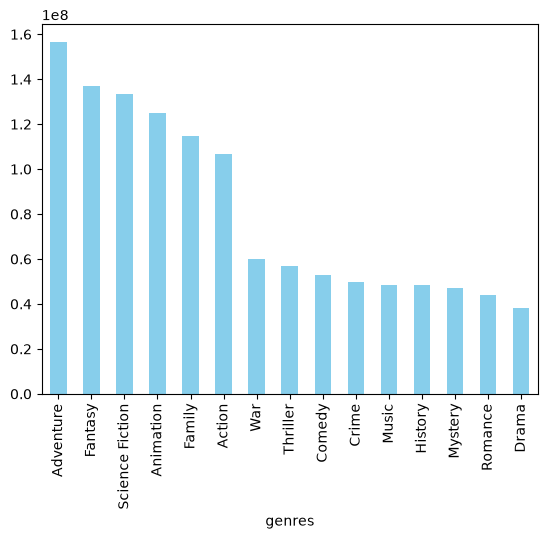

In [153]:
genre_rev.head(15).plot(kind='bar',color='skyblue')

### From EDA
#### * revenue strongly influenced by genre,budget,popularity
#### * Adventure,fantacy,Scienceficture,animation,family are high revenue
#### * higher budget is higher revenue
#### * some outliers such as major block

# Step 5 : Feature Engineering
### nammakitta iruka feature ah model ku thaguntha mari change pandrathu

In [154]:
df=df_explode.copy()

In [155]:
## step1 : handle skweness in target

In [156]:
df['log_revenue']=np.log1p(df['revenue'])
df['log_revenue'].head()

0   20.53
0   20.53
0   20.53
1   20.37
1   20.37
Name: log_revenue, dtype: float64

In [157]:
# step 2 :Numerical feature

In [158]:
numerical_feature=df.select_dtypes(include='number').columns.tolist()
numerical_feature
numerical_feature1 = [col for col in numerical_feature if col not in ['revenue', 'log_revenue']]
numerical_feature1

['budget',
 'vote_average',
 'vote_count',
 'runtime',
 'popularity',
 'release_year']

In [159]:
numerical_transformer= Pipeline(steps=[('miising',SimpleImputer(strategy='median')),('scalar',StandardScaler())])

In [160]:
## step 3 : Date Feature(release_month,quarter)

In [161]:
df['release_month']=pd.to_datetime(df['release_date']).dt.month.fillna(0).astype(int)

In [162]:
df['release_month'].head()

0     7
0     7
0     7
1    11
1    11
Name: release_month, dtype: int64

In [163]:
df['release_quarter']=pd.to_datetime(df['release_date']).dt.quarter.fillna(0).astype(int)
df['release_quarter'].head()

0    3
0    3
0    3
1    4
1    4
Name: release_quarter, dtype: int64

In [164]:
date_col=['release_month','release_quarter']
date_col

['release_month', 'release_quarter']

In [165]:
date_transformer=StandardScaler()

In [166]:
## step 4 : generes(multi-label-multi-hot-encoding)

In [167]:
df['genres']

0                   Action
0          Science Fiction
0                Adventure
1                Adventure
1                    Drama
                ...       
1538538              Drama
1538538             Family
1538756             Comedy
1538756              Drama
1538756           Thriller
Name: genres, Length: 33929, dtype: str

In [168]:
multi_hot=pd.get_dummies(df,columns=['genres'],prefix='genre',dtype=int)
multi_hot

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,production_companies,original_language,release_year,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_TV Movie,genre_Thriller,genre_War,genre_Western
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00",...,0,0,0,0,0,0,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00",...,0,0,0,0,0,0,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00",...,0,0,0,0,0,0,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00",...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538538,195,0.00,0,2021-08-17,98,13,0.60,NaN,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538538,195,0.00,0,2021-08-17,98,13,0.60,NaN,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538756,10,0.00,0,NaN,5,159,0.60,NaN,en,NaN,...,0,0,0,0,0,0,0,0,0,0
1538756,10,0.00,0,NaN,5,159,0.60,NaN,en,NaN,...,0,0,0,0,0,0,0,0,0,0


In [169]:
df=multi_hot.groupby(multi_hot.index).max()
df

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,production_companies,original_language,release_year,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_TV Movie,genre_Thriller,genre_War,genre_Western
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,"Legendary Pictures, Syncopy, Warner Bros. Pict...",en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,"Legendary Pictures, Syncopy, Lynda Obst Produc...",en,"2,014.00",...,0,0,0,0,0,1,0,0,0,0
2,185000000,8.51,30619,2008-07-16,1004558444,152,130.64,"DC Comics, Legendary Pictures, Syncopy, Isobel...",en,"2,008.00",...,0,0,0,0,0,0,0,1,0,0
3,237000000,7.57,29815,2009-12-15,2923706026,162,79.93,"Dune Entertainment, Lightstorm Entertainment, ...",en,"2,009.00",...,0,0,0,0,0,1,0,0,0,0
4,220000000,7.71,29166,2012-04-25,1518815515,143,98.08,Marvel Studios,en,"2,012.00",...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538241,100,0.00,0,2020-08-04,200,19,0.60,EOR Productions,en,"2,020.00",...,0,0,0,0,0,0,0,0,0,0
1538496,750,0.00,0,NaN,99,17,0.60,NaN,en,NaN,...,0,0,0,0,0,0,0,0,0,0
1538512,98,0.00,0,2021-12-23,98,10,0.60,SineSibol,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538538,195,0.00,0,2021-08-17,98,13,0.60,NaN,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0


In [170]:
# step 1 : convert into the list

In [171]:
df['production_companies']=df['production_companies'].fillna(',').str.split(',')
df['production_companies'].head()

0    [Legendary Pictures,  Syncopy,  Warner Bros. P...
1    [Legendary Pictures,  Syncopy,  Lynda Obst Pro...
2    [DC Comics,  Legendary Pictures,  Syncopy,  Is...
3    [Dune Entertainment,  Lightstorm Entertainment...
4                                     [Marvel Studios]
Name: production_companies, dtype: object

In [172]:
# step 2 using explode to convert the individual row

In [173]:
df_explode=df.explode('production_companies')
df_explode

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,production_companies,original_language,release_year,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_TV Movie,genre_Thriller,genre_War,genre_Western
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Legendary Pictures,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Syncopy,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Warner Bros. Pictures,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Legendary Pictures,en,"2,014.00",...,0,0,0,0,0,1,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Syncopy,en,"2,014.00",...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538512,98,0.00,0,2021-12-23,98,10,0.60,SineSibol,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538538,195,0.00,0,2021-08-17,98,13,0.60,,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538538,195,0.00,0,2021-08-17,98,13,0.60,,tl,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1538756,10,0.00,0,NaN,5,159,0.60,,en,NaN,...,0,0,0,0,0,0,0,1,0,0


In [174]:
df_clean = df_explode[df_explode['production_companies'] != '']
df_clean

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,production_companies,original_language,release_year,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_TV Movie,genre_Thriller,genre_War,genre_Western
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Legendary Pictures,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Syncopy,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,Warner Bros. Pictures,en,"2,010.00",...,0,0,0,0,0,1,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Legendary Pictures,en,"2,014.00",...,0,0,0,0,0,1,0,0,0,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,Syncopy,en,"2,014.00",...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537072,200,0.00,0,2020-03-07,200,9,0.60,Gila Film,en,"2,020.00",...,0,0,0,0,0,0,0,0,0,0
1537758,50,0.00,0,2021-02-27,98,9,0.60,SineSibol,en,"2,021.00",...,0,0,0,0,0,0,0,0,0,0
1537876,1000000,0.00,0,NaN,100000000,120,0.60,Royston G King Group,en,NaN,...,0,0,0,0,0,0,0,0,0,0
1538241,100,0.00,0,2020-08-04,200,19,0.60,EOR Productions,en,"2,020.00",...,0,0,0,0,0,0,0,0,0,0


In [175]:
# step 3 : remove the whitespace if white space in the column

In [176]:
df_clean['production_companies']=df_clean['production_companies'].str.strip()
df_clean['production_companies']

0             Legendary Pictures
0                        Syncopy
0          Warner Bros. Pictures
1             Legendary Pictures
1                        Syncopy
                   ...          
1537072                Gila Film
1537758                SineSibol
1537876     Royston G King Group
1538241          EOR Productions
1538512                SineSibol
Name: production_companies, Length: 32852, dtype: str

In [177]:
# step 4 identify the top 20 companies

In [178]:
top_companies=df_clean['production_companies'].value_counts().head(20)
top_companies

production_companies
Warner Bros. Pictures        655
Universal Pictures           591
Paramount                    487
20th Century Fox             486
Columbia Pictures            457
Metro-Goldwyn-Mayer          376
New Line Cinema              239
Walt Disney Pictures         198
Canal+                       188
Touchstone Pictures          165
Miramax                      159
Lionsgate                    158
United Artists               151
StudioCanal                  135
Summit Entertainment         126
Relativity Media             124
DreamWorks Pictures          123
TriStar Pictures             119
Focus Features               107
Village Roadshow Pictures     98
Name: count, dtype: int64

In [179]:
df_clean['production_companies']=df_clean['production_companies'].apply(lambda x : x if x in top_companies else 'other')
df_clean['production_companies']

0                          other
0                          other
0          Warner Bros. Pictures
1                          other
1                          other
                   ...          
1537072                    other
1537758                    other
1537876                    other
1538241                    other
1538512                    other
Name: production_companies, Length: 32852, dtype: str

In [180]:
## multi-encoding 

In [181]:
multi_hot_prod=pd.get_dummies(df_clean,columns=['production_companies'],prefix='company',dtype=int)
multi_hot_prod

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,original_language,release_year,log_revenue,...,company_StudioCanal,company_Summit Entertainment,company_Touchstone Pictures,company_TriStar Pictures,company_United Artists,company_Universal Pictures,company_Village Roadshow Pictures,company_Walt Disney Pictures,company_Warner Bros. Pictures,company_other
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,en,"2,010.00",20.53,...,0,0,0,0,0,0,0,0,0,1
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,en,"2,010.00",20.53,...,0,0,0,0,0,0,0,0,0,1
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,en,"2,010.00",20.53,...,0,0,0,0,0,0,0,0,1,0
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,en,"2,014.00",20.37,...,0,0,0,0,0,0,0,0,0,1
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,en,"2,014.00",20.37,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537072,200,0.00,0,2020-03-07,200,9,0.60,en,"2,020.00",5.30,...,0,0,0,0,0,0,0,0,0,1
1537758,50,0.00,0,2021-02-27,98,9,0.60,en,"2,021.00",4.60,...,0,0,0,0,0,0,0,0,0,1
1537876,1000000,0.00,0,NaN,100000000,120,0.60,en,NaN,18.42,...,0,0,0,0,0,0,0,0,0,1
1538241,100,0.00,0,2020-08-04,200,19,0.60,en,"2,020.00",5.30,...,0,0,0,0,0,0,0,0,0,1


In [182]:
## convert into one row

In [183]:
df=multi_hot_prod.groupby(multi_hot_prod.index).max()
df.head()

,budget,vote_average,vote_count,release_date,revenue,runtime,popularity,original_language,release_year,log_revenue,...,company_StudioCanal,company_Summit Entertainment,company_Touchstone Pictures,company_TriStar Pictures,company_United Artists,company_Universal Pictures,company_Village Roadshow Pictures,company_Walt Disney Pictures,company_Warner Bros. Pictures,company_other
0,160000000,8.36,34495,2010-07-15,825532764,148,83.95,en,"2,010.00",20.53,...,0,0,0,0,0,0,0,0,1,1
1,165000000,8.42,32571,2014-11-05,701729206,169,140.24,en,"2,014.00",20.37,...,0,0,0,0,0,0,0,0,0,1
2,185000000,8.51,30619,2008-07-16,1004558444,152,130.64,en,"2,008.00",20.73,...,0,0,0,0,0,0,0,0,1,1
3,237000000,7.57,29815,2009-12-15,2923706026,162,79.93,en,"2,009.00",21.80,...,0,0,0,0,0,0,0,0,0,1
4,220000000,7.71,29166,2012-04-25,1518815515,143,98.08,en,"2,012.00",21.14,...,0,0,0,0,0,0,0,0,0,1


In [184]:
## step 6 : original language top(10)

In [185]:
top_language=df['original_language'].value_counts().head(10)
top_language

original_language
en    9186
hi     327
fr     297
es     246
ru     211
ja     127
ta     108
zh     101
it      99
ko      88
Name: count, dtype: int64

In [186]:
df['original_language']=df['original_language'].apply(lambda x : x if x in top_language else 'other')

In [187]:
## using onehot engoding because one movie have a one language

In [188]:
lang_encode=OneHotEncoder(handle_unknown='ignore')
categorical_feature=['original_language']

In [189]:
# step 7 : ColumTransformer Setup

In [190]:
preproccessor=ColumnTransformer(transformers=[('num',numerical_transformer,numerical_feature1),('date',date_transformer,date_col),('cat',lang_encode,categorical_feature)],remainder='passthrough')

# Step 8: train-test-split

In [191]:
X = df.drop(columns=['revenue', 'log_revenue','release_date'])
y = df['log_revenue']  

In [192]:
## train test split

In [193]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [194]:
x_train_pre=preproccessor.fit_transform(x_train)
x_test_pre=preproccessor.transform(x_test)

# Step 9 : Model Building & Evaluation

In [195]:
model={'linear_regression': LinearRegression(),
      'Lasso_reg': Lasso(alpha=0.001),
       'Ridge_reg': Ridge(1.0),
      'Random Forest': RandomForestRegressor(n_estimators=100,random_state=42),
      'xboost': XGBRegressor(n_estimators=200,random_state=42,learning_rate=0.1)}

In [196]:
result=[]
for name,m in model.items():
    m.fit(x_train_pre,y_train)
    y_pred=m.predict(x_test_pre)
    
    mae=mean_absolute_error(y_test,y_pred)
    mse=mean_squared_error(y_test,y_pred)
    rmse=np.sqrt(mse)
    r2=r2_score(y_test,y_pred)

    result.append([name,mae,mse,rmse,r2])
    

In [197]:
result_df=pd.DataFrame(result,columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']).sort_values(by='R2',ascending=False)
result_df

,Model,MAE,MSE,RMSE,R2
4,xboost,1.15,3.58,1.89,0.85
3,Random Forest,1.18,3.74,1.94,0.84
1,Lasso_reg,2.32,10.43,3.23,0.56
0,linear_regression,2.32,10.43,3.23,0.56
2,Ridge_reg,2.32,10.43,3.23,0.56


In [198]:
## i choose xboost and Randomforest model 

# Feature Important

In [200]:
## feature importance for xgregressor

In [206]:
feature_name=preproccessor.get_feature_names_out()
xgb_model=model['xboost']
xg_feature_importance=xgb_model.feature_importances_
xgb_important_df=pd.DataFrame({'feature_names':feature_name,'importance':xg_feature_importance}).sort_values(by='importance',ascending=False)
xgb_important_df.head(15)


,feature_names,importance
0,num__budget,0.42
2,num__vote_count,0.09
13,cat__original_language_ja,0.02
54,remainder__company_Universal Pictures,0.02
4,num__popularity,0.02
24,remainder__genre_Documentary,0.02
8,cat__original_language_en,0.02
10,cat__original_language_fr,0.02
18,cat__original_language_zh,0.02
11,cat__original_language_hi,0.02


In [207]:
## visualize

C:\Users\ROBIN\AppData\Local\Temp\ipykernel_13412\1742090482.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_important_df.head(15),x='importance',y='feature_names',palette='YlGnBu')


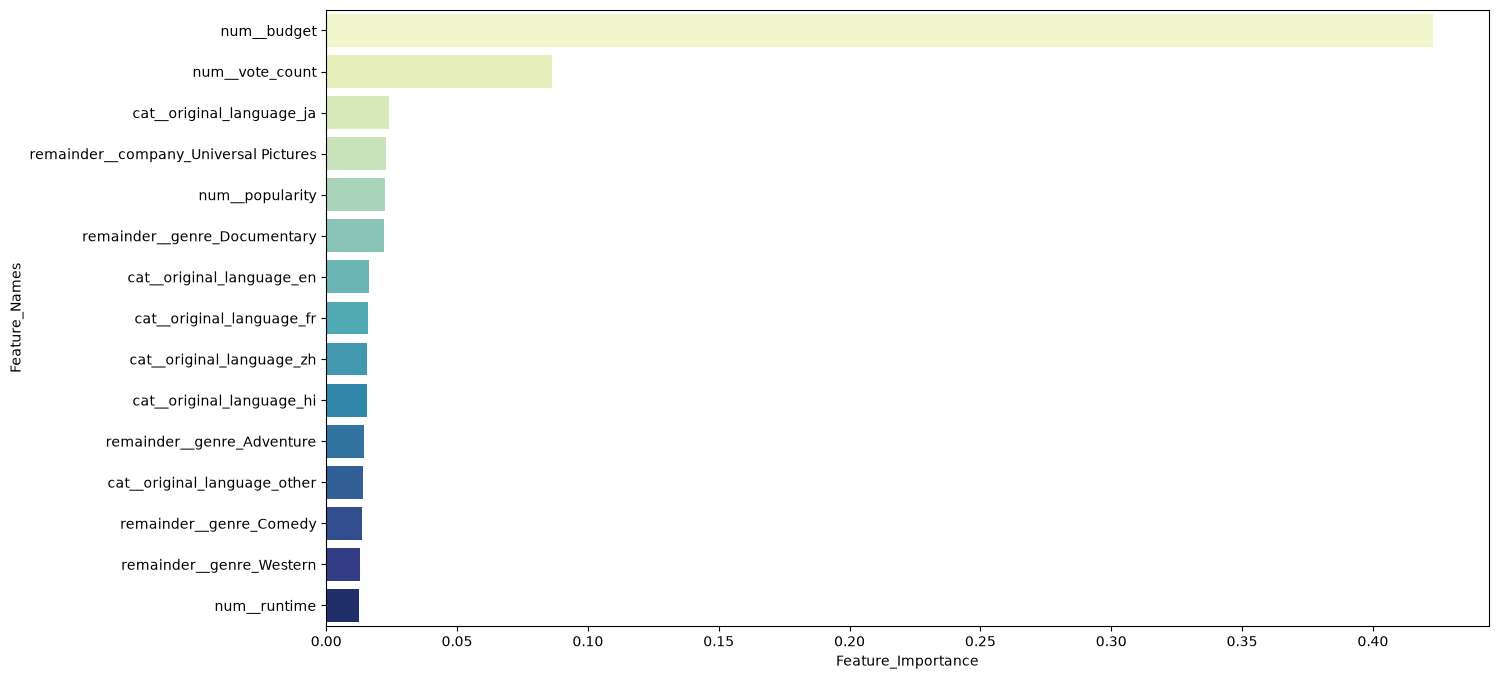

In [218]:
plt.figure(figsize=(15,8))
sns.barplot(data=xgb_important_df.head(15),x='importance',y='feature_names',palette='YlGnBu')
plt.xlabel('Feature_Importance')
plt.ylabel('Feature_Names')
plt.show()

In [219]:
## feature importance for Random forest

In [224]:
feature_name=preproccessor.get_feature_names_out()
random_model=model['Random Forest']
ran_feature_imp=random_model.feature_importances_
rf_feature_df=pd.DataFrame({'feature_name':feature_name,'feature_importance':ran_feature_imp})
rf_feature_df.head(10)

,feature_name,feature_importance
0,num__budget,0.79
1,num__vote_average,0.01
2,num__vote_count,0.09
3,num__runtime,0.02
4,num__popularity,0.02
5,num__release_year,0.02
6,date__release_month,0.01
7,date__release_quarter,0.00
8,cat__original_language_en,0.00
9,cat__original_language_es,0.00


C:\Users\ROBIN\AppData\Local\Temp\ipykernel_13412\2805131180.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_feature_df.head(10),y='feature_name',x='feature_importance',palette='viridis')


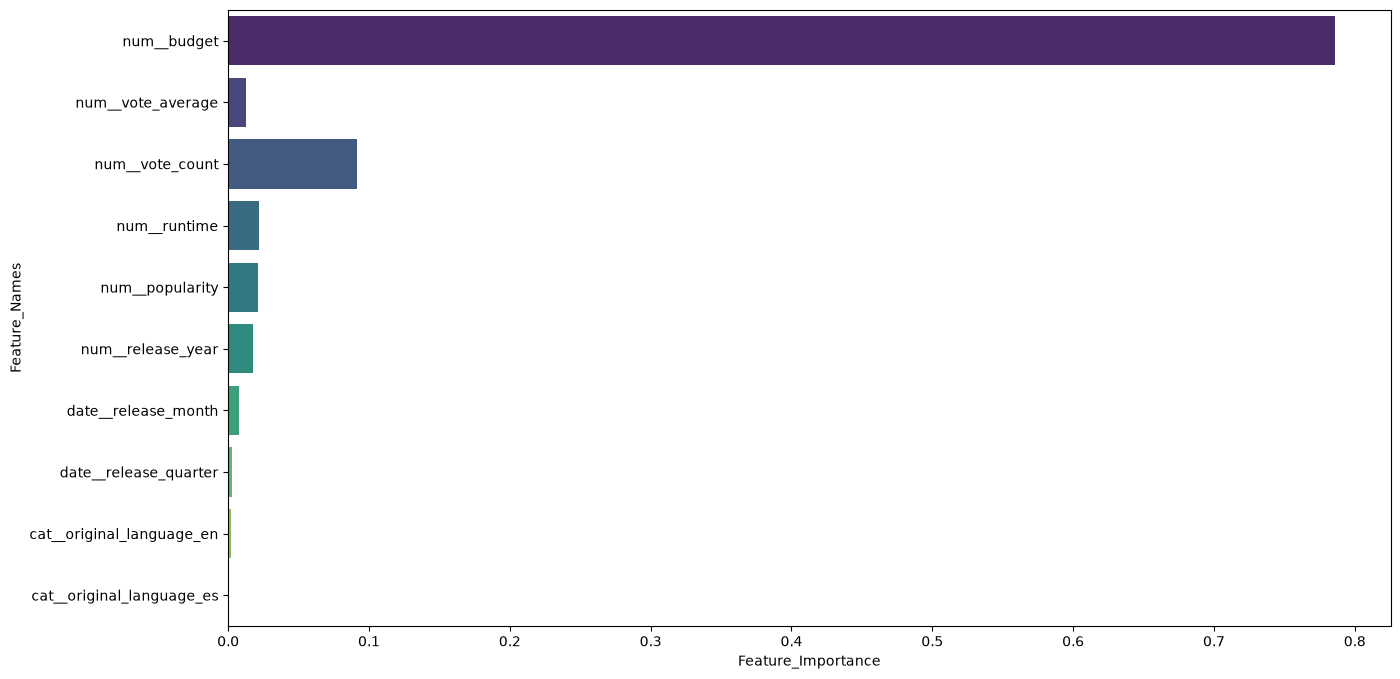

In [228]:
plt.figure(figsize=(15,8))
sns.barplot(data=rf_feature_df.head(10),y='feature_name',x='feature_importance',palette='viridis')
plt.xlabel('Feature_Importance')
plt.ylabel('Feature_Names')
plt.show()

In [229]:
## Hyperparameter tuning using RandomSerchCv

In [231]:
## for xboost

In [237]:
xgb_model=XGBRegressor(objective='reg:squarederror',random_state=42)

In [238]:
param_dict = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6, 8],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 1.5, 2]
}

In [266]:
rns=RandomizedSearchCV(estimator=xgb_model,param_distributions=param_dict,scoring='r2',cv=3,n_jobs=-1,random_state=42,verbose=2,n_iter=30)

In [267]:
rns.fit(x_train_pre,y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function which

In [268]:
rns.best_params_


{'subsample': 0.6,
 'reg_lambda': 2,
 'reg_alpha': 1,
 'n_estimators': 100,
 'min_child_weight': 7,
 'max_depth': 8,
 'learning_rate': 0.1,
 'colsample_bytree': 0.6}

In [269]:
rns.best_score_

np.float64(0.8724464192266884)

In [270]:
best_model=rns.best_estimator_


In [271]:
## evaluate on test set

In [272]:
best_y_pred=best_model.predict(x_test_pre)
print(r2_score(y_test,best_y_pred))
print(mean_squared_error(y_test,best_y_pred))
print(mean_absolute_error(y_test,best_y_pred))

0.8470361050061087
3.6145403529532225
1.1645042003141401


C:\Users\ROBIN\AppData\Local\Temp\ipykernel_13412\1270775879.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=best_model_df.head(15),x='feature_important',y='feature_names',palette='viridis')


<Axes: xlabel='feature_important', ylabel='feature_names'>

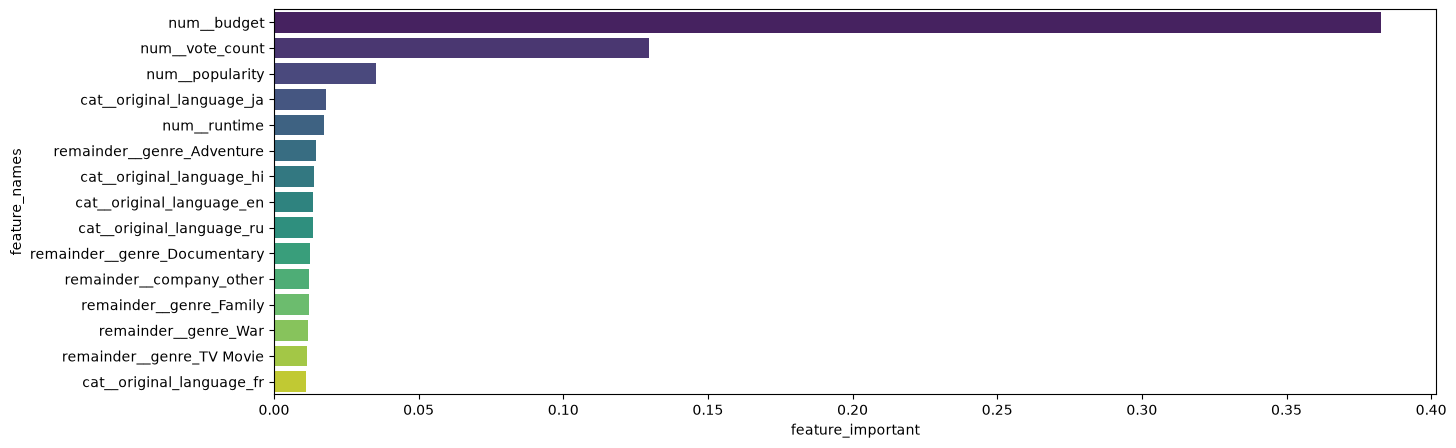

In [273]:
## feature importance
feature_name=preproccessor.get_feature_names_out()
feature_importance=best_model.feature_importances_
best_model_df=pd.DataFrame({'feature_names':feature_name,'feature_important':feature_importance}).sort_values(by='feature_important',ascending=False)

## visualize
plt.figure(figsize=(15,5))
sns.barplot(data=best_model_df.head(15),x='feature_important',y='feature_names',palette='viridis')

In [257]:
## hyperparametre tuning for random forest

In [264]:
random_forest_mod=RandomForestRegressor()

In [265]:
param_dict_rn = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.8, 1.0],
    'bootstrap': [True]
}

In [275]:
randomized=RandomizedSearchCV(estimator=random_forest_mod,param_distributions=param_dict_rn,cv=3,verbose=2,n_jobs=-1,random_state=42,n_iter=30,scoring='r2')

In [276]:
randomized.fit(x_train_pre,y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True], 'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selecte

In [281]:
print(randomized.best_params_)
print(randomized.best_score_)
best_estimater=randomized.best_estimator_
y_test_pred_rn=best_estimater.predict(x_test_pre)
print(r2_score(y_test,y_test_pred_rn))

{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.8, 'max_depth': None, 'bootstrap': True}
0.8723255440880885
0.8427942083218266


C:\Users\ROBIN\AppData\Local\Temp\ipykernel_13412\3601130021.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=best_model_df.head(10),x='feature_important',y='feature_names',palette='viridis')


<Axes: xlabel='feature_important', ylabel='feature_names'>

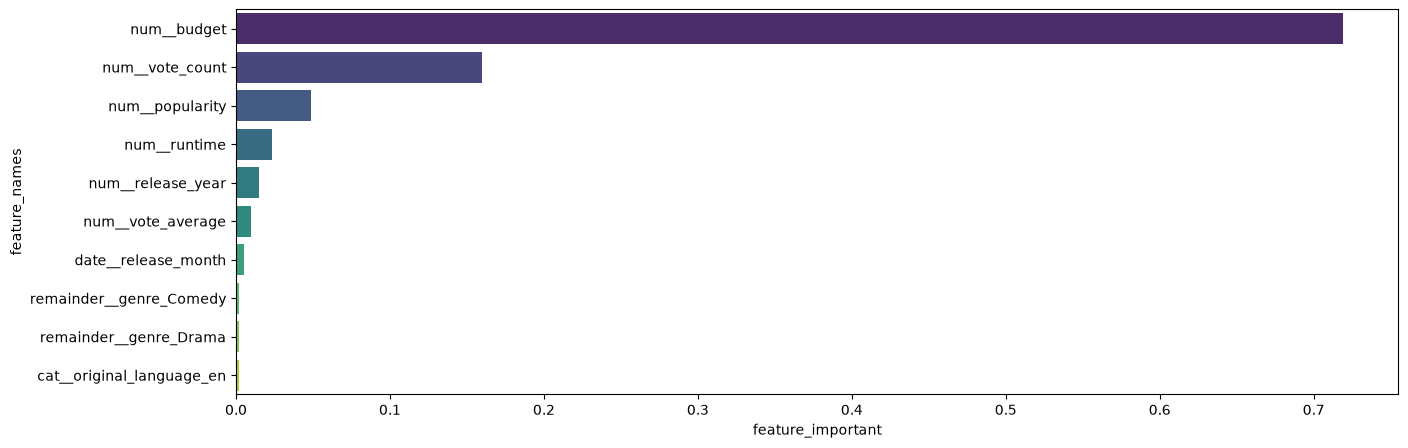

In [283]:
## feature importance
feature_name=preproccessor.get_feature_names_out()
feature_importance=best_estimater.feature_importances_
best_model_df=pd.DataFrame({'feature_names':feature_name,'feature_important':feature_importance}).sort_values(by='feature_important',ascending=False)

## visualize
plt.figure(figsize=(15,5))
sns.barplot(data=best_model_df.head(10),x='feature_important',y='feature_names',palette='viridis')